# Demo SuperPoint + SuperGLUE

Github Repositories
- SuperGLUE: https://github.com/magicleap/SuperGluePretrainedNetwork  
- hpatches dataset: https://github.com/hpatches/hpatches-dataset


In [3]:
# Clone Github repository
!git clone https://github.com/magicleap/SuperGluePretrainedNetwork.git

# Download and extract HPatches Sequences
!wget https://huggingface.co/datasets/vbalnt/hpatches/resolve/main/hpatches-sequences-release.zip
!7z x hpatches-sequences-release.zip

fatal: destination path 'SuperGluePretrainedNetwork' already exists and is not an empty directory.
zsh:1: command not found: wget
zsh:1: command not found: 7z


## Read Image and Homography


module://matplotlib_inline.backend_inline
Image 1 shape: (973, 1068, 3)
Image 2 shape: (653, 986, 3)
Points shape: (5, 2)


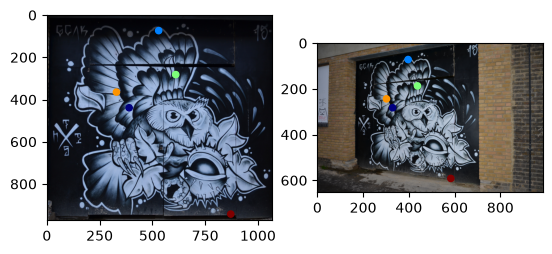

In [5]:
import cv2, numpy as np, random
import matplotlib.pyplot as plt
from matplotlib import cm
import matplotlib

print(matplotlib.get_backend())

category = "v_bird"
image1_path = f"hpatches-sequences-release/{category}/1.ppm"
image2_path = f"hpatches-sequences-release/{category}/2.ppm"
H12_path = f"hpatches-sequences-release/{category}/H_1_2"

# read images and homography matrix
image1 = cv2.imread(image1_path, 1) # 0: grayscale | 1: bgr
image2 = cv2.imread(image2_path, 1) # 0: grayscale | 1: bgr
H = np.loadtxt(H12_path)

# Check image shape
print("Image 1 shape:", image1.shape)
print("Image 2 shape:", image2.shape)

h1, w1 = image1.shape[:2]
h2, w2 = image2.shape[:2]

# generate random points
num_points = 5
np.random.seed(58) #reproducibility
pts = np.random.rand(num_points, 2,) * np.array([w1,h1])
print("Points shape:", pts.shape)

# Project transformation
pts = np.hstack([pts, np.ones((num_points,1))]) # [x,y,1]
pts_t = (H @ pts.T).T
pts_t = pts_t[:, :2] / pts_t[:, 2:3]

# Plot Figures
fig, ax = plt.subplots(1,2)
colors = cm.jet(np.linspace(0,1, len(pts)))
ax[0].imshow(cv2.cvtColor(image1, cv2.COLOR_BGR2RGB))
ax[0].scatter(pts[:,0], pts[:,1], s=20, c=colors)
ax[1].imshow(cv2.cvtColor(image2, cv2.COLOR_BGR2RGB))
ax[1].scatter(pts_t[:,0], pts_t[:,1], s=20, c=colors)
plt.show()

## DEMO SuperPoint + SuperGlue

In [6]:
# Import Models
import torch
from SuperGluePretrainedNetwork.models.superglue import SuperGlue
from SuperGluePretrainedNetwork.models.superpoint import SuperPoint

device= "cuda" if torch.cuda.is_available() else "cpu"
print('Running inference on device \"{}\"'.format(device))

superpoint = SuperPoint(dict(
    nms_radius=4,
    keypoint_threshold=0.5,
    max_keypoints=40
    )).eval().to(device)


superglue = SuperGlue(dict(
    weights='outdoor',  # 'indoor' or 'outdoor'
    sinkhorn_iterations=20,
    match_threshold=0.2,
    )).eval().to(device)

Running inference on device "cpu"
Loaded SuperPoint model
Loaded SuperGlue model ("outdoor" weights)


## Detect keypoints and Match

In [ ]:
# detect keypoints and compute local descriptors
from SuperGluePretrainedNetwork.models.utils import read_image
from SuperGluePretrainedNetwork.models.utils import make_matching_plot
matplotlib.use("Agg")

superpoint.config['max_keypoints'] = 100

resize = [640, 480] #

# read images with resize transformation
image0, inp0, scales0 = read_image(image1_path, device, resize, 0, resize_float=False)
image1, inp1, scales1 = read_image(image2_path, device, resize, 0, resize_float=False)

# prepare data for superpoint model
data = {'image0': inp0, 'image1': inp1}

with torch.no_grad():

    # Extract Keypoints with superpoint for both images
    pred0 = superpoint({'image': data['image0']})
    pred1 = superpoint({'image': data['image1']})

    # Merge representations into a single dictionary structure
    data = {**data,**{k+'0': v for k, v in pred0.items()}}
    data = {**data,**{k+'1': v for k, v in pred1.items()}}

    for k in data:
        if isinstance(data[k], (list, tuple)):
            data[k] = torch.stack(data[k])
        print(f"Key={k} Dtype={type(data[k])} Shape:{data[k].shape}")

    # Compute Matches with superglue
    out_match = superglue(data)
    pred = {**data,  **out_match}
    pred = {k: v[0].cpu().numpy() for k, v in pred.items()}


# print(pred.keys())
kpts0, kpts1 = pred['keypoints0'], pred['keypoints1']
matches, conf = pred['matches0'], pred['matching_scores0']

out_matches = {
    'keypoints0': kpts0,
    'keypoints1': kpts1,
    'matches': matches,
    'match_confidence': conf
}

valid = (matches > -1) # valid matches have value greater than -1
mkpts0 = kpts0[valid]
mkpts1 = kpts1[matches[valid]]
mconf = conf[valid]
print(f"Found {len(mkpts0)} matches")

Key=image0 Dtype=<class 'torch.Tensor'> Shape:torch.Size([1, 1, 480, 640])
Key=image1 Dtype=<class 'torch.Tensor'> Shape:torch.Size([1, 1, 480, 640])
Key=keypoints0 Dtype=<class 'torch.Tensor'> Shape:torch.Size([1, 97, 2])
Key=scores0 Dtype=<class 'torch.Tensor'> Shape:torch.Size([1, 97])
Key=descriptors0 Dtype=<class 'torch.Tensor'> Shape:torch.Size([1, 256, 97])
Key=keypoints1 Dtype=<class 'torch.Tensor'> Shape:torch.Size([1, 100, 2])
Key=scores1 Dtype=<class 'torch.Tensor'> Shape:torch.Size([1, 100])
Key=descriptors1 Dtype=<class 'torch.Tensor'> Shape:torch.Size([1, 256, 100])
Found 26 matches


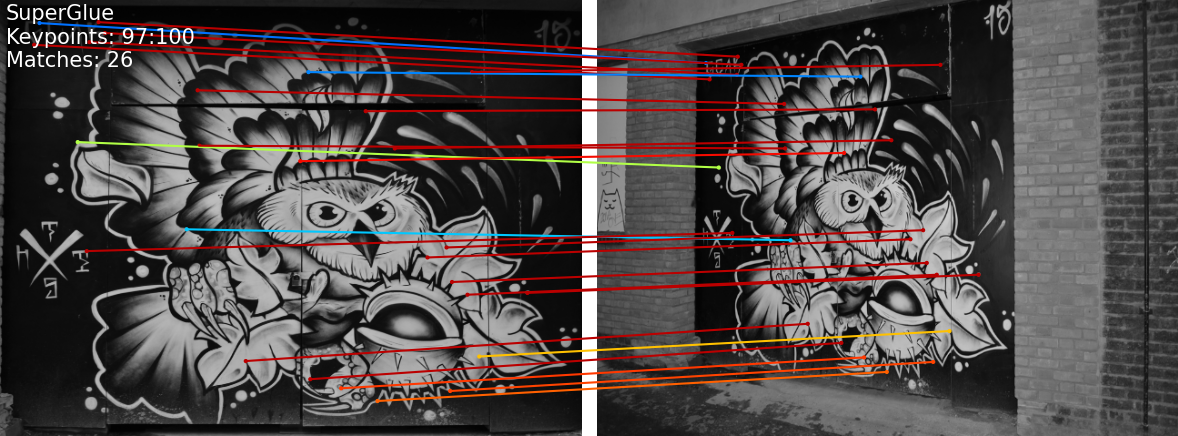

In [ ]:
from PIL import Image
text = [
    'SuperGlue',
    'Keypoints: K0{}:K1{}'.format(len(kpts0), len(kpts1)),
    'Matches: {}'.format(len(mkpts0)),
]

make_matching_plot(
    image0, image1,
    kpts0, kpts1,
    mkpts0, mkpts1,
    color = cm.jet(mconf),
    text=text,
    path="test.png",
    show_keypoints=False,
    fast_viz=False,
    opencv_display=False
    )

small_text = "\n".join(text)
display(Image.open("test.png"))

## Saving and loading Matlab files

In [ ]:
import scipy.io

A = np.array([[1, 2], [3, 4]])
print("Array")
print(A)
scipy.io.savemat('test.mat', mdict={'A': A})

# load matlab file
mat = scipy.io.loadmat('test.mat')
print(mat['A'])

Array
[[1 2]
 [3 4]]
[[1 2]
 [3 4]]


In [ ]:
# Save outputs to matlab
out_matches = {
    'keypoints0': kpts0,
    'keypoints1': kpts1,
    'matches': matches,
    'match_confidence': conf
}

scipy.io.savemat('output.mat', mdict=out_matches)
